# Subject-Independent Motor-Imagery EEG Classification

**Research objective.** Build and evaluate a reproducible binary classifier for left-fist (`T1`) versus right-fist (`T2`) motor imagery using the PhysioNet EEGMMIDB dataset.

**Research questions.** (1) How strong is a within-subject CSP+LDA baseline? (2) How well does EEGNet generalize to subjects never seen during training? (3) What evidence and limitations should be reported rather than hidden behind a single accuracy value?

The test subjects are isolated before model selection. Test data is evaluated only once at the end.

In [11]:
%pip install mne numpy pandas matplotlib scikit-learn torch -q

from pathlib import Path
import copy
import json
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import torch
import torch.nn as nn
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
mne.set_log_level('WARNING')
DATA_DIR = Path(r'C:\SEM_7\PhaseProject\eeg-motor-movementimagery-dataset-1.0.0\files')
OUT_DIR = DATA_DIR.parent / 'outputs_research'
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS = [4, 8, 12]
ALL_SUBJECTS = range(1, 110)
assert DATA_DIR.is_dir(), f'Missing dataset directory: {DATA_DIR}'
print('Dataset:', DATA_DIR)
print('Outputs:', OUT_DIR)

Note: you may need to restart the kernel to use updated packages.
Dataset: C:\SEM_7\PhaseProject\eeg-motor-movementimagery-dataset-1.0.0\files
Outputs: C:\SEM_7\PhaseProject\eeg-motor-movementimagery-dataset-1.0.0\outputs_research



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Loading and preprocessing

Runs 4, 8, and 12 contain the two-class motor-imagery task. Every subject receives the same preprocessing: 8-30 Hz band-pass, common-average reference, baseline correction, and a 1-4 second classification window.

In [2]:
def load_subject_raw(subject_id):
    raws = []
    subject_dir = DATA_DIR / f'S{subject_id:03d}'
    for run in RUNS:
        path = subject_dir / f'S{subject_id:03d}R{run:02d}.edf'
        if path.exists():
            raws.append(mne.io.read_raw_edf(path, preload=True, verbose=False))
    if not raws: return None
    raw = mne.concatenate_raws(raws)
    if raw.info['sfreq'] != 160.0: raw.resample(160.0, npad='auto', verbose=False)
    raw.rename_channels(lambda name: name.strip('.'))
    raw.set_montage('standard_1005', on_missing='ignore')
    return raw

def make_epochs(raw):
    raw.filter(8.0, 30.0, fir_design='firwin', skip_by_annotation='edge', verbose=False)
    raw.set_eeg_reference('average', projection=False, verbose=False)
    events, event_id = mne.events_from_annotations(raw, verbose=False)
    event_id = {name: code for name, code in event_id.items() if name in ('T1', 'T2')}
    if len(event_id) != 2: return None
    epochs = mne.Epochs(raw, events, event_id=event_id, tmin=-1.0, tmax=4.0, baseline=(-1.0, 0.0), picks='eeg', preload=True, reject_by_annotation=True, verbose=False)
    return epochs.crop(tmin=1.0, tmax=4.0)

In [3]:
# Sanity check before the full experiment.
for subject_id in (1, 2, 3):
    raw = load_subject_raw(subject_id)
    epochs = make_epochs(raw) if raw is not None else None
    if epochs is not None:
        print(f'S{subject_id:03d}: sfreq={epochs.info["sfreq"]}, channels={len(epochs.ch_names)}, epochs={len(epochs)}, classes={epochs.event_id}')
    else:
        print(f'S{subject_id:03d}: unavailable or missing both classes')

C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')


S001: sfreq=160.0, channels=64, epochs=45, classes={'T1': 2, 'T2': 3}


C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')


S002: sfreq=160.0, channels=64, epochs=45, classes={'T1': 2, 'T2': 3}


C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')


S003: sfreq=160.0, channels=64, epochs=45, classes={'T1': 2, 'T2': 3}


## 2. Within-subject CSP+LDA baseline

CSP is fitted inside each cross-validation training fold. This baseline measures performance when the person contributes training data and must not be reported as cross-subject generalization.

In [4]:
csp_results = []
for subject_id in range(1, 21):
    raw = load_subject_raw(subject_id)
    epochs = make_epochs(raw) if raw is not None else None
    if epochs is None or len(epochs) < 10: continue
    X_subject = epochs.get_data(copy=False)
    y_subject = epochs.events[:, -1]
    if len(np.unique(y_subject)) != 2: continue
    pipeline = Pipeline([('csp', CSP(n_components=6, reg='ledoit_wolf', log=True, norm_trace=False)), ('lda', LinearDiscriminantAnalysis())])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    scores = []; f1_scores = []
    for train_idx, valid_idx in cv.split(X_subject, y_subject):
        pipeline.fit(X_subject[train_idx], y_subject[train_idx])
        prediction = pipeline.predict(X_subject[valid_idx])
        scores.append(accuracy_score(y_subject[valid_idx], prediction))
        f1_scores.append(f1_score(y_subject[valid_idx], prediction, average='macro'))
    csp_results.append({'subject': subject_id, 'accuracy': np.mean(scores), 'macro_f1': np.mean(f1_scores)})
csp_df = pd.DataFrame(csp_results)
display(csp_df)
print('Mean within-subject accuracy:', csp_df.accuracy.mean())
print('Mean within-subject macro-F1:', csp_df.macro_f1.mean())
csp_df.to_csv(OUT_DIR / 'csp_lda_within_subject.csv', index=False)

C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local

,subject,accuracy,macro_f1
0,1,0.555556,0.541450
1,2,0.866667,0.864957
2,3,0.577778,0.571537
3,4,0.511111,0.493203
4,5,0.577778,0.534186
5,6,0.622222,0.596623
6,7,0.955556,0.955000
7,8,0.355556,0.348889
8,9,0.511111,0.476234
9,10,0.577778,0.522735


Mean within-subject accuracy: 0.5722222222222222
Mean within-subject macro-F1: 0.5531643356643358


## 3. Subject-independent dataset and split

All epochs retain their subject ID. A two-stage grouped split creates train, validation, and final test subjects. The disjointness assertions are part of the experiment, not optional commentary.

In [5]:
epoch_sets = []; subject_labels = []
for subject_id in ALL_SUBJECTS:
    raw = load_subject_raw(subject_id)
    epochs = make_epochs(raw) if raw is not None else None
    if epochs is None or len(epochs) == 0 or len(np.unique(epochs.events[:, -1])) != 2: continue
    epoch_sets.append(epochs); subject_labels.extend([subject_id] * len(epochs))
epochs_all = mne.concatenate_epochs(epoch_sets)
X = epochs_all.get_data(copy=False).astype(np.float32)
raw_labels = epochs_all.events[:, -1]
groups = np.asarray(subject_labels)
labels = np.sort(np.unique(raw_labels))
y = (raw_labels == labels[1]).astype(np.int64)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_valid_idx, test_idx = next(gss_test.split(X, y, groups=groups))
gss_valid = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=43)
train_rel, valid_rel = next(gss_valid.split(X[train_valid_idx], y[train_valid_idx], groups=groups[train_valid_idx]))
train_idx = train_valid_idx[train_rel]; valid_idx = train_valid_idx[valid_rel]
train_subjects = sorted(set(groups[train_idx])); valid_subjects = sorted(set(groups[valid_idx])); test_subjects = sorted(set(groups[test_idx]))
assert set(train_subjects).isdisjoint(valid_subjects) and set(train_subjects).isdisjoint(test_subjects) and set(valid_subjects).isdisjoint(test_subjects)
print('X:', X.shape, 'subjects:', len(np.unique(groups)), 'classes:', labels)
print('Train:', len(train_idx), train_subjects)
print('Validation:', len(valid_idx), valid_subjects)
print('Test:', len(test_idx), test_subjects)
np.save(OUT_DIR / 'subject_split.npy', {'train_subjects': train_subjects, 'validation_subjects': valid_subjects, 'test_subjects': test_subjects}, allow_pickle=True)

C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local\Temp\ipykernel_24880\2799558339.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005', on_missing='ignore')
C:\Users\keert\AppData\Local

X: (4898, 64, 481) subjects: 109 classes: [2 3]
Train: 3115 [np.int64(6), np.int64(7), np.int64(9), np.int64(10), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(21), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(44), np.int64(45), np.int64(47), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(66), np.int64(67), np.int64(68), np.int64(70), np.int64(72), np.int64(74), np.int64(75), np.int64(76), np.int64(77), np.int64(78), np.int64(83), np.int64(84), np.int64(86), np.int64(87), np.int64(88), np.int64(89), np.int64(90), np.int64(91), np.int64(92), np.int64(94), np.int64(95), np.int64(96), np.int64(98), np.int64(99), np.int64(102), np.int64(105), np.int64(106), n

In [6]:
# Per-epoch, per-channel normalization does not use data from another subject.
X_norm = (X - X.mean(axis=2, keepdims=True)) / (X.std(axis=2, keepdims=True) + 1e-6)
def loader(indices, shuffle):
    data = torch.tensor(X_norm[indices], dtype=torch.float32).unsqueeze(1)
    target = torch.tensor(y[indices], dtype=torch.long)
    return DataLoader(TensorDataset(data, target), batch_size=64, shuffle=shuffle)
train_loader = loader(train_idx, True); valid_loader = loader(valid_idx, False); test_loader = loader(test_idx, False)

## 4. EEGNet training and validation-only model selection

The model is selected using validation subjects. The test loader is deliberately absent from the training loop. For a final research run, increase epochs as needed and record the environment and seed.

In [7]:
class EEGNet(nn.Module):
    def __init__(self, channels, samples, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, (1, 64), padding=(0, 32), bias=False), nn.BatchNorm2d(8),
            nn.Conv2d(8, 16, (channels, 1), groups=8, bias=False), nn.BatchNorm2d(16), nn.ELU(), nn.AvgPool2d((1, 4)), nn.Dropout(dropout),
            nn.Conv2d(16, 16, (1, 16), padding=(0, 8), groups=16, bias=False), nn.Conv2d(16, 16, (1, 1), bias=False), nn.BatchNorm2d(16), nn.ELU(), nn.AvgPool2d((1, 8)), nn.Dropout(dropout)
        )
        with torch.no_grad():
            flat_dim = self.features(torch.zeros(1, 1, channels, samples)).flatten(1).shape[1]
        self.classifier = nn.Linear(flat_dim, 2)
    def forward(self, x): return self.classifier(self.features(x).flatten(1))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = EEGNet(X.shape[1], X.shape[2]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=8, factor=0.5)
criterion = nn.CrossEntropyLoss(); best_state = None; best_valid = -np.inf; patience = 0
train_losses = []; valid_scores = []
for epoch in range(150):
    model.train(); total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device); optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step(); total_loss += loss.item() * len(xb)
    train_losses.append(total_loss / len(train_loader.dataset))
    model.eval(); correct = 0
    with torch.no_grad():
        for xb, yb in valid_loader:
            correct += (model(xb.to(device)).argmax(1).cpu() == yb).sum().item()
    valid_accuracy = correct / len(valid_loader.dataset); valid_scores.append(valid_accuracy); scheduler.step(valid_accuracy)
    if valid_accuracy > best_valid:
        best_valid = valid_accuracy; best_state = copy.deepcopy(model.state_dict()); patience = 0
    else: patience += 1
    if (epoch + 1) % 10 == 0: print(f'Epoch {epoch + 1}: loss={train_losses[-1]:.4f}, validation_accuracy={valid_accuracy:.4f}')
    if patience >= 25: break
model.load_state_dict(best_state)
print('Best validation accuracy:', best_valid)

Epoch 10: loss=0.6658, validation_accuracy=0.5764
Epoch 20: loss=0.6094, validation_accuracy=0.6040
Epoch 30: loss=0.5817, validation_accuracy=0.5902
Epoch 40: loss=0.5653, validation_accuracy=0.5890
Best validation accuracy: 0.6177944862155389


## 5. Final unseen-subject evaluation

This is the only cell that evaluates the final test set. Interpret the result with subject-level variability, class balance, and repeated splits in mind.

Final unseen-subject accuracy: 0.5838
Final unseen-subject macro-F1: 0.5838
              precision    recall  f1-score   support

          T1     0.5890    0.5795    0.5842       497
          T2     0.5786    0.5881    0.5833       488

    accuracy                         0.5838       985
   macro avg     0.5838    0.5838    0.5838       985
weighted avg     0.5838    0.5838    0.5838       985



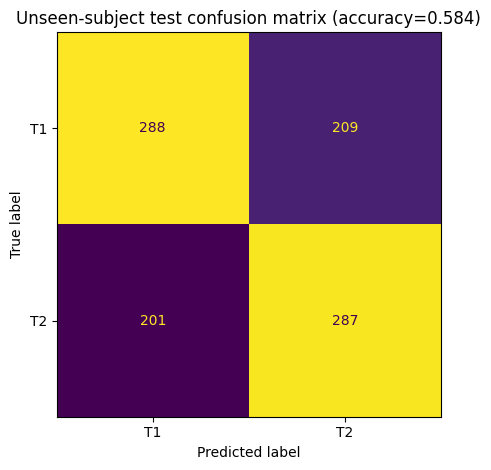

In [9]:
model.eval(); predictions = []; truth = []
with torch.no_grad():
    for xb, yb in test_loader:
        predictions.extend(model(xb.to(device)).argmax(1).cpu().numpy()); truth.extend(yb.numpy())
predictions = np.asarray(predictions); truth = np.asarray(truth)
test_accuracy = accuracy_score(truth, predictions); test_f1 = f1_score(truth, predictions, average='macro')
print(f'Final unseen-subject accuracy: {test_accuracy:.4f}')
print(f'Final unseen-subject macro-F1: {test_f1:.4f}')
print(classification_report(truth, predictions, target_names=['T1', 'T2'], digits=4))
report = {'seed': SEED, 'accuracy': float(test_accuracy), 'macro_f1': float(test_f1), 'n_test_epochs': int(len(truth)), 'test_subjects': [int(subject_id) for subject_id in test_subjects]}
(OUT_DIR / 'final_metrics.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
cm = confusion_matrix(truth, predictions)
ConfusionMatrixDisplay(cm, display_labels=['T1', 'T2']).plot(colorbar=False); plt.title(f'Unseen-subject test confusion matrix (accuracy={test_accuracy:.3f})'); plt.tight_layout(); plt.savefig(OUT_DIR / 'final_confusion_matrix.png', dpi=150); plt.show()

## Research interpretation and next experiments

A result near binary chance is still informative: cross-subject EEG transfer is difficult, and effective sample size is closer to the number of independent subjects than the number of epochs. Do not claim clinical or real-time usefulness from this baseline alone.

Recommended follow-up experiments are repeated subject splits with confidence intervals, training-only channel normalization, a fixed central motor-cortex channel subset, consistent artifact handling as an ablation, and lightweight calibration using data from a new participant.